# Titanic: Data Cleaning & Exploratory Data Analysis

**Goal:** clean the Titanic training data, explore relationships between variables, and identify patterns that explain who survived.

**Dataset:** Kaggle Titanic (`train.csv`, 891 passengers).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/train.csv")

## 1. Data overview

In [2]:
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [5]:
print("Duplicate rows:", df.duplicated().sum())
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "pct": (missing/len(df)*100).round(1)})[missing > 0]

Duplicate rows: 0


,missing,pct
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


**Observations**
- `Age` is missing for 177 passengers (about 20%), `Cabin` for 687 (about 77%), `Embarked` for 2.
- There are no duplicate rows.
- `Fare` is heavily right-skewed (max about $512) and 15 passengers have a fare of 0.

## 2. Data cleaning

### 2.1 Embarked (2 missing): fill with the mode

In [6]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

### 2.2 Cabin (77% missing): too sparse to impute
Instead of filling it, convert it into two informative features: whether a cabin was recorded, and the deck letter.

In [7]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("Unknown")
df = df.drop(columns="Cabin")

### 2.3 Age (177 missing): impute by title
A global mean would ignore that ages differ a lot by group (a "Master" is a young boy, "Mrs" is typically older). So extract the title from `Name` and fill with the median age of each title.

In [8]:
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Miss", "Mrs", "Master"]), "Rare")

print(df.groupby("Title")["Age"].median())
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64


### 2.4 Fare: skew and zero values
The 15 zero-fare rows are kept since they are real records, but a log transform is used for plotting and modeling.

In [9]:
print("Skew before:", round(df["Fare"].skew(), 2))
df["LogFare"] = np.log1p(df["Fare"])
print("Skew after: ", round(df["LogFare"].skew(), 2))

Skew before: 4.79
Skew after:  0.39


### 2.5 Feature engineering

In [10]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["AgeGroup"] = pd.cut(df["Age"], [0, 12, 18, 35, 60, 100],
                        labels=["Child", "Teen", "Adult", "Middle", "Senior"])

In [11]:
print("Remaining missing values:", df.isnull().sum().sum())
df.head()

Remaining missing values: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin,Deck,Title,LogFare,FamilySize,IsAlone,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0,Unknown,Mr,2.110213,2,0,Adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1,C,Mrs,4.280593,2,0,Middle
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0,Unknown,Miss,2.188856,1,1,Adult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1,C,Mrs,3.990834,2,0,Adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0,Unknown,Mr,2.202765,1,1,Adult


## 3. Univariate analysis

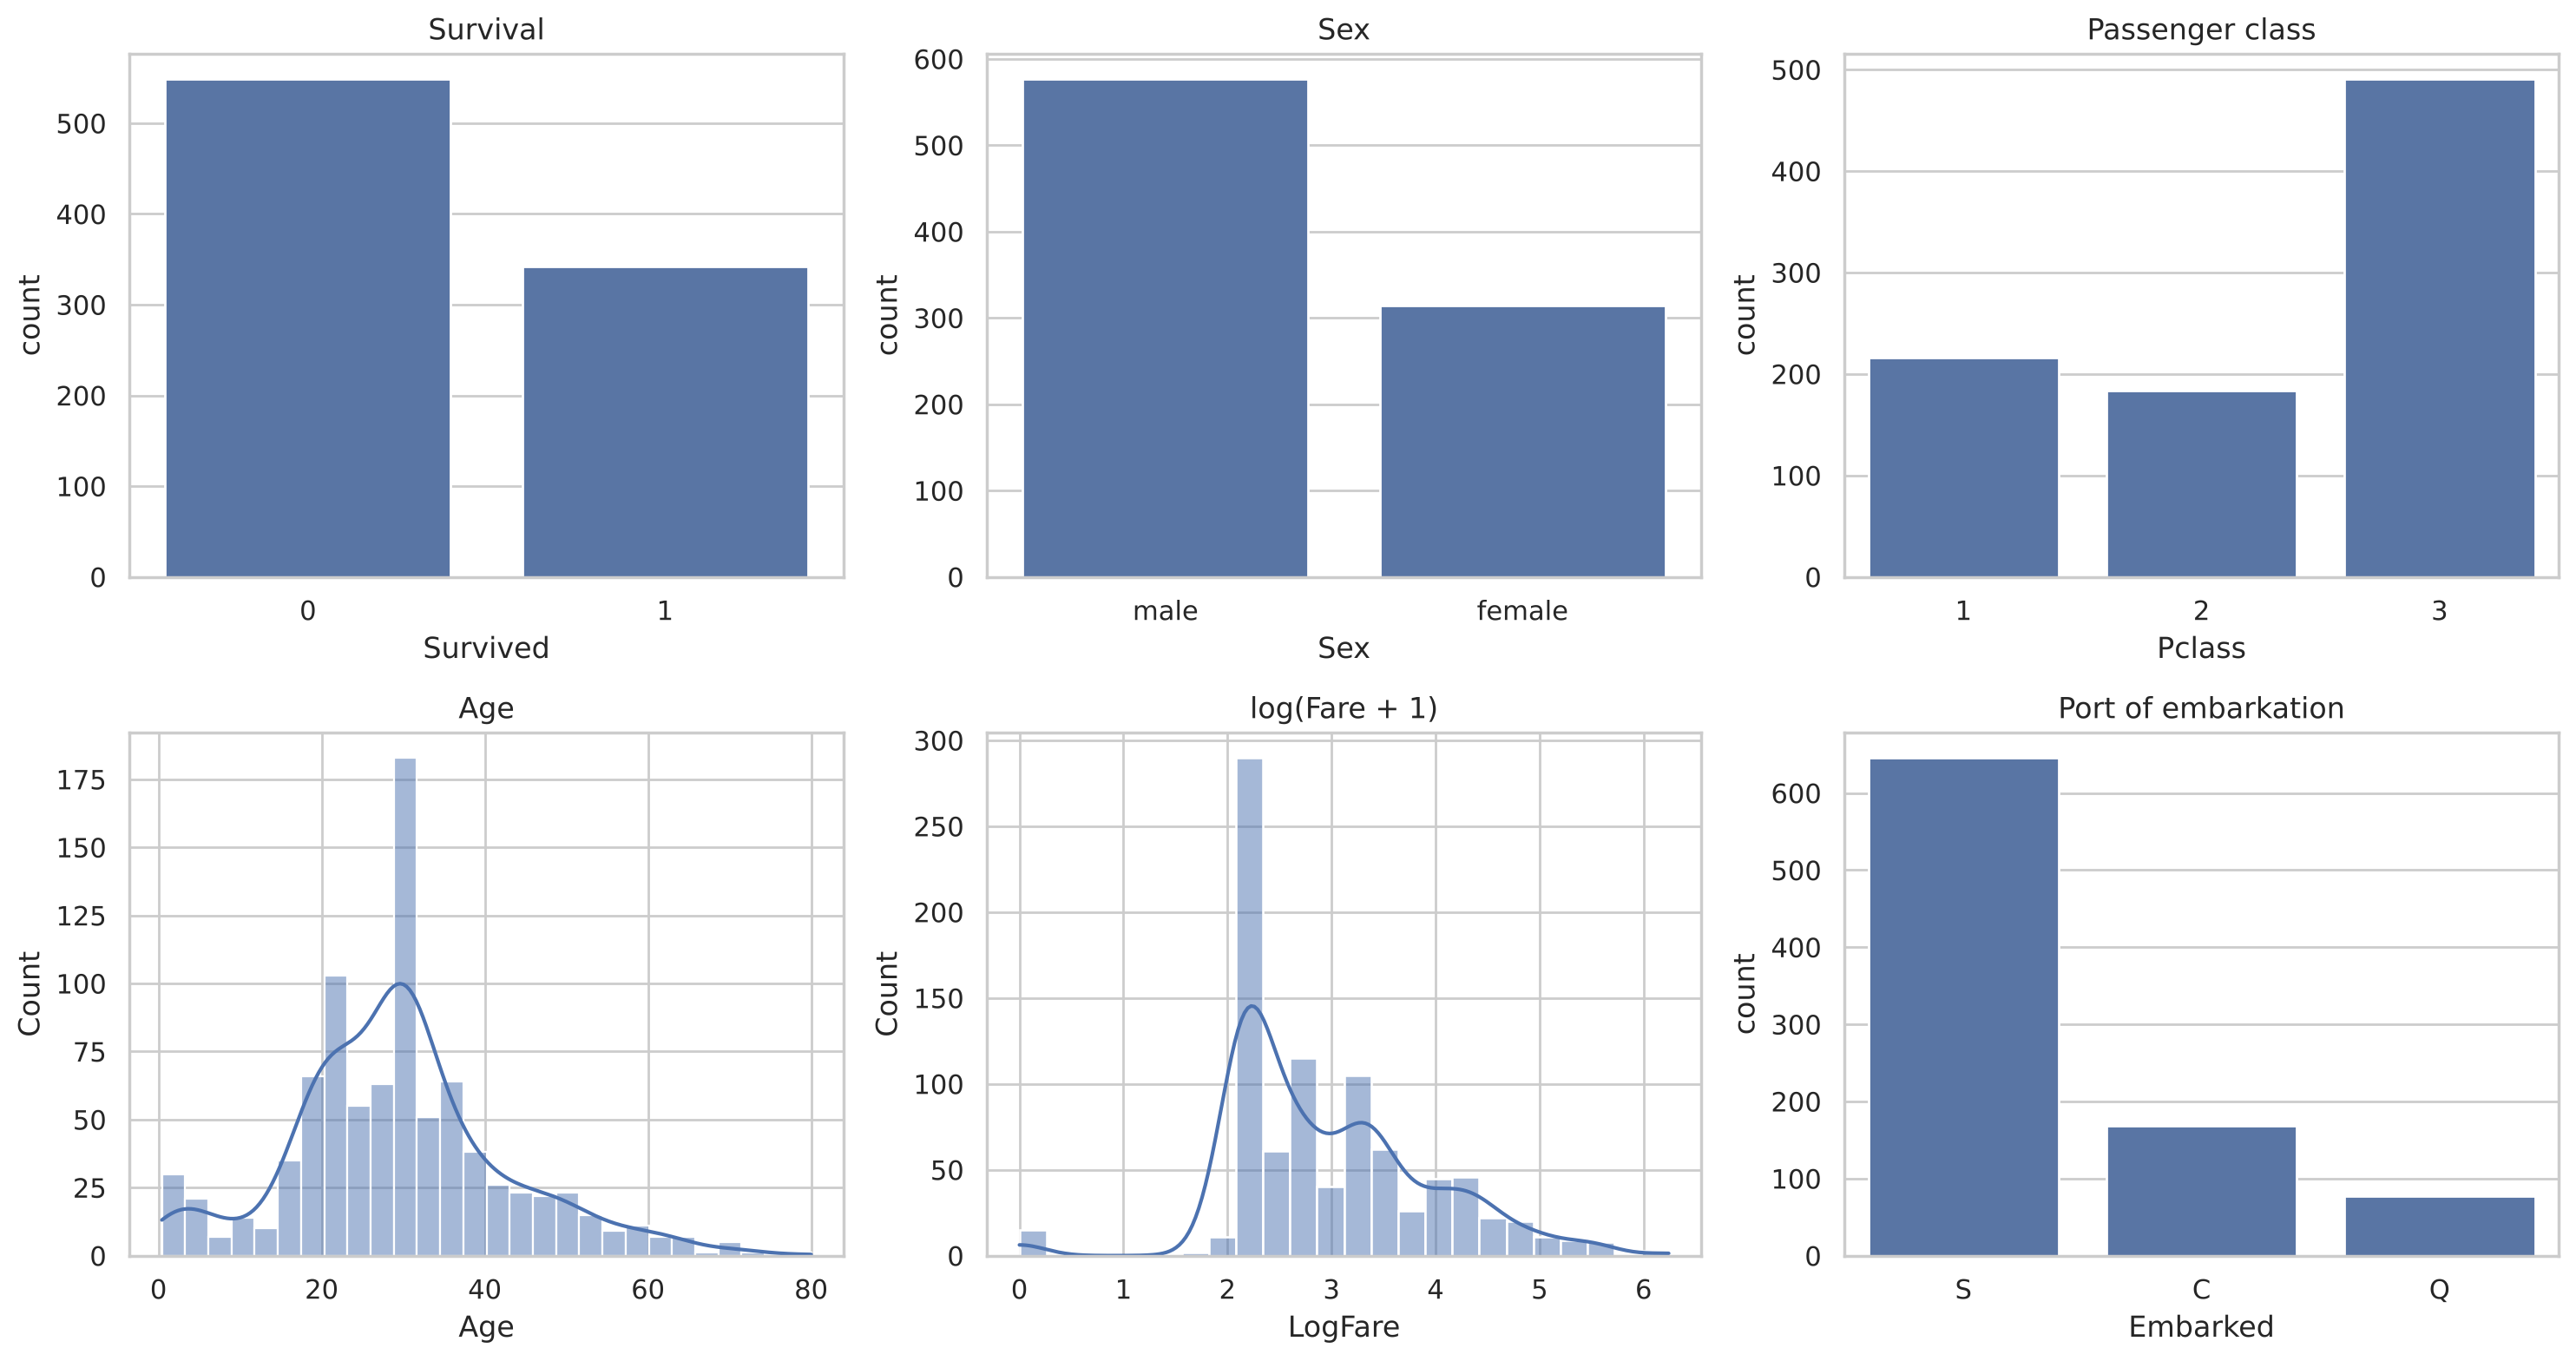

Overall survival rate: 0.384


In [12]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(data=df, x="Survived", ax=ax[0, 0]).set_title("Survival")
sns.countplot(data=df, x="Sex", ax=ax[0, 1]).set_title("Sex")
sns.countplot(data=df, x="Pclass", ax=ax[0, 2]).set_title("Passenger class")
sns.histplot(df["Age"], kde=True, ax=ax[1, 0]).set_title("Age")
sns.histplot(df["LogFare"], kde=True, ax=ax[1, 1]).set_title("log(Fare + 1)")
sns.countplot(data=df, x="Embarked", ax=ax[1, 2]).set_title("Port of embarkation")
plt.tight_layout(); plt.show()
print("Overall survival rate:", round(df["Survived"].mean(), 3))

- Only **38.4%** survived.
- Men (577) far outnumber women (314).
- 3rd class is more than half of all passengers (491).

## 4. Bivariate analysis: survival vs. each variable

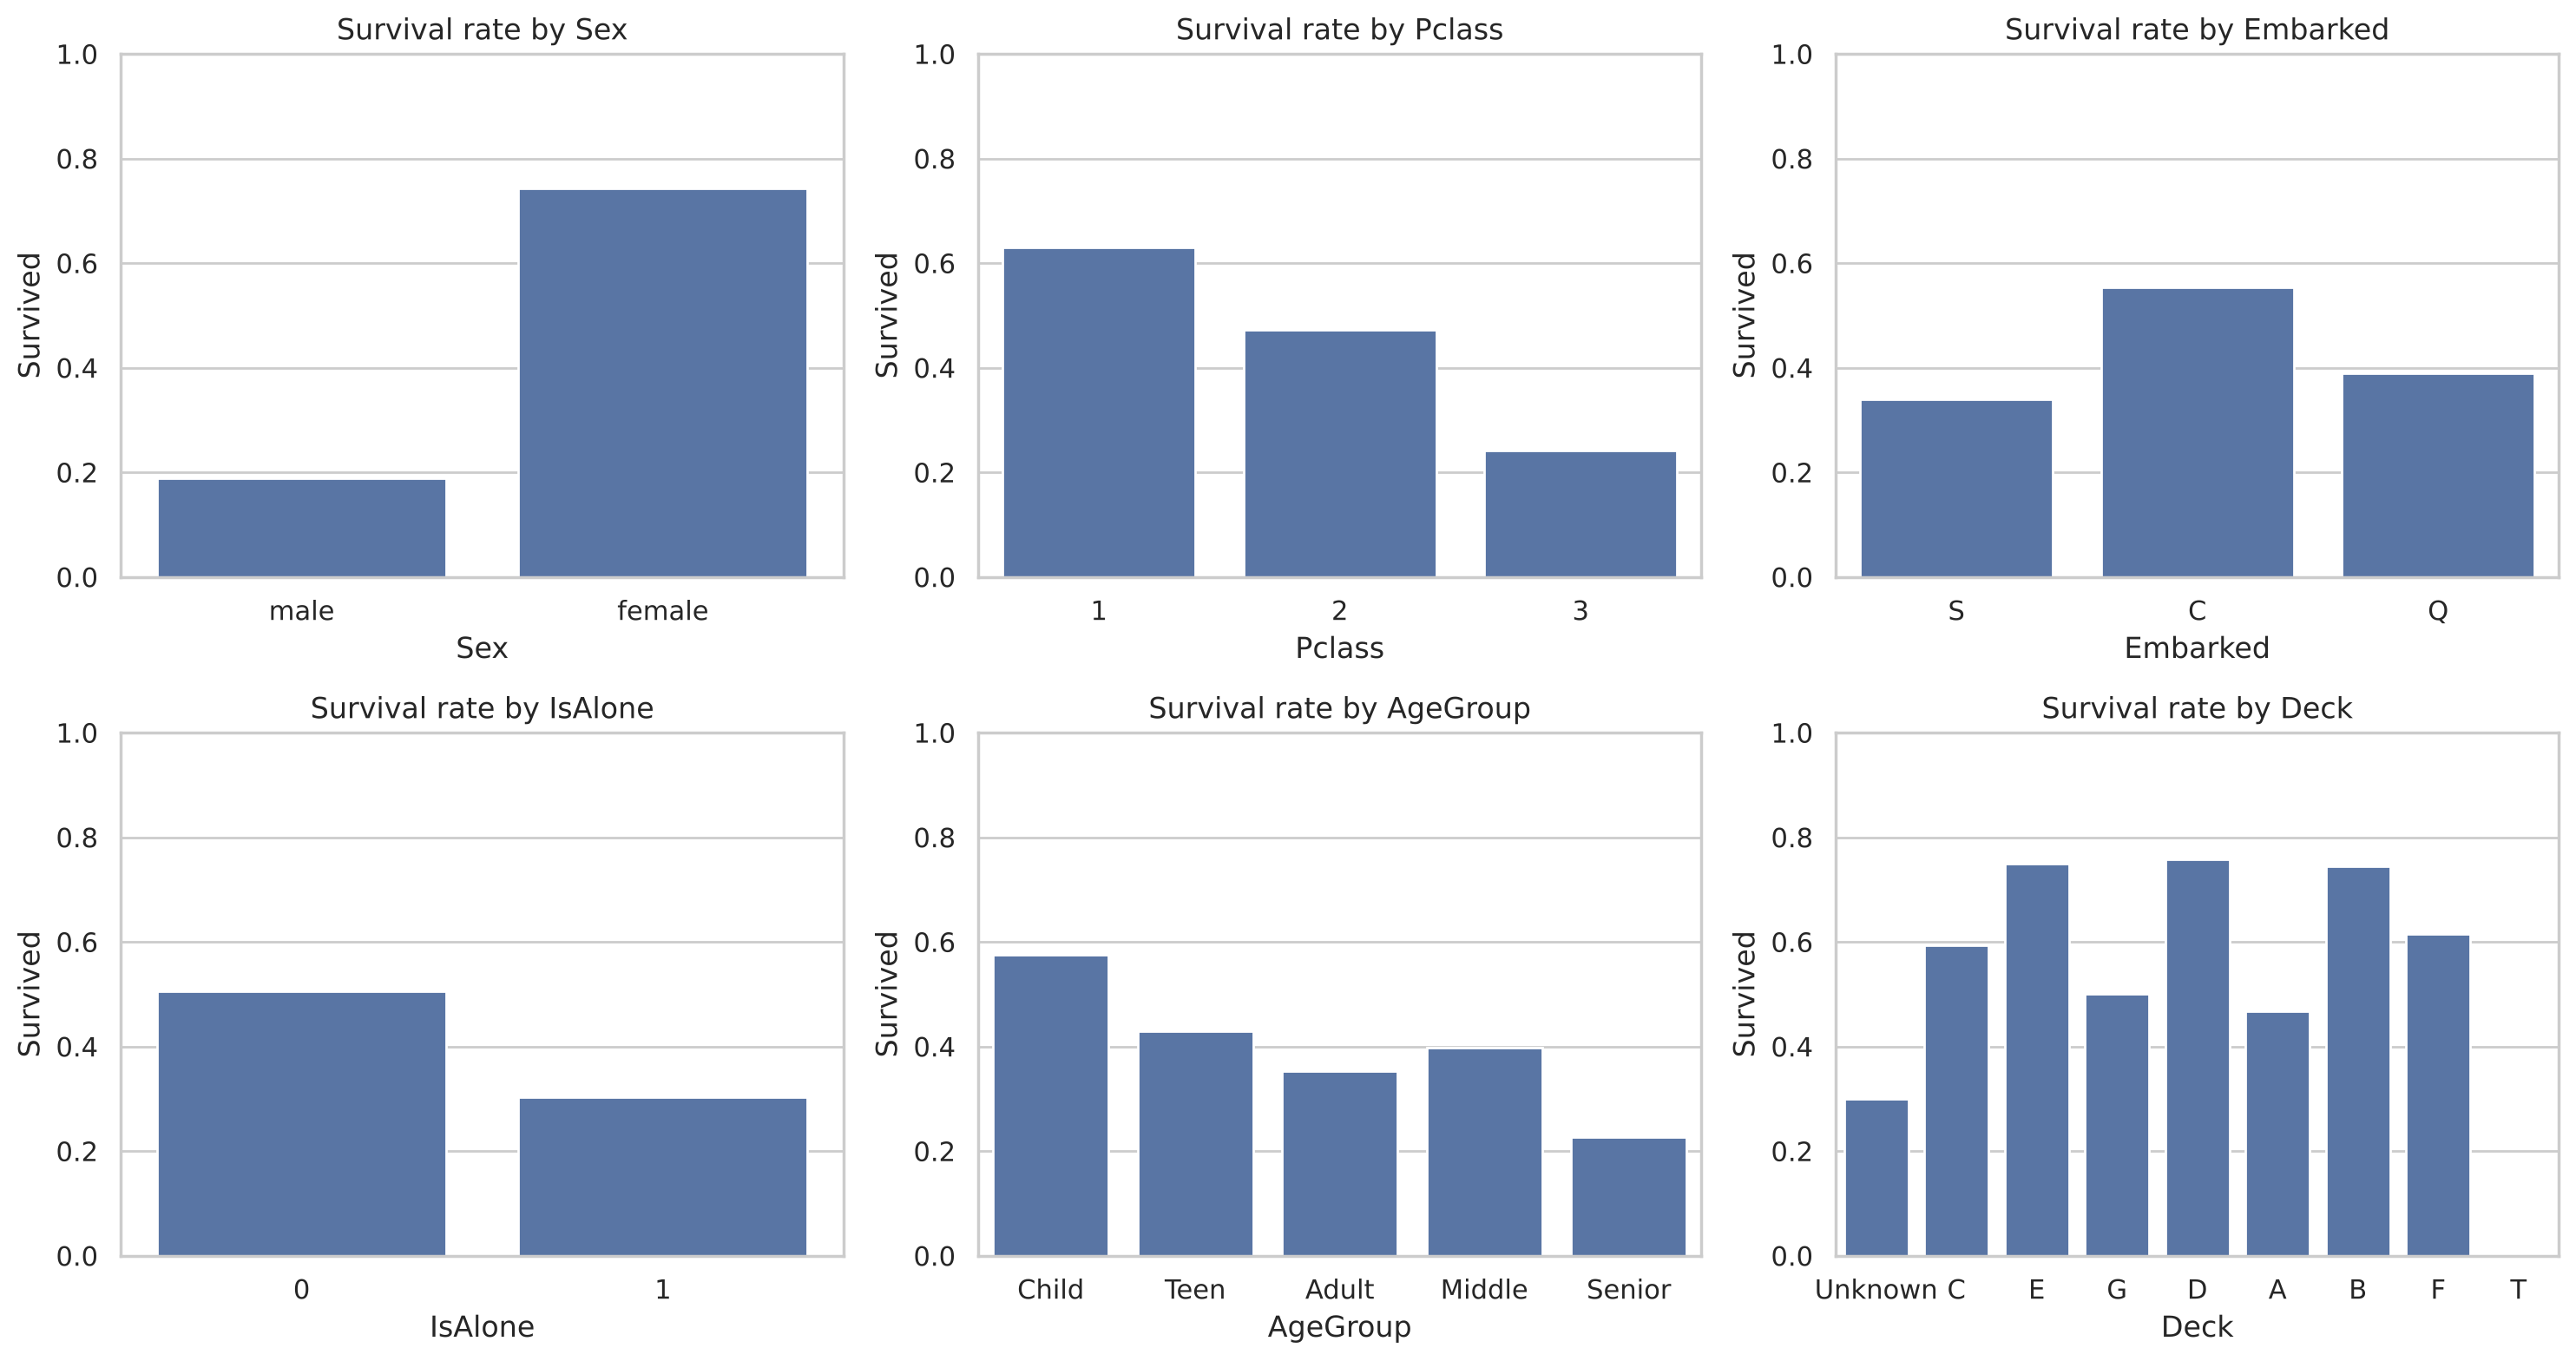

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, col in zip(ax.flat, ["Sex", "Pclass", "Embarked", "IsAlone", "AgeGroup", "Deck"]):
    sns.barplot(data=df, x=col, y="Survived", ax=a, errorbar=None)
    a.set_title(f"Survival rate by {col}"); a.set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [14]:
for col in ["Sex", "Pclass", "Embarked"]:
    print(df.groupby(col)["Survived"].agg(["mean", "count"]).round(3), "\n")

         mean  count
Sex                 
female  0.742    314
male    0.189    577 

         mean  count
Pclass              
1       0.630    216
2       0.473    184
3       0.242    491 

           mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.339    646 



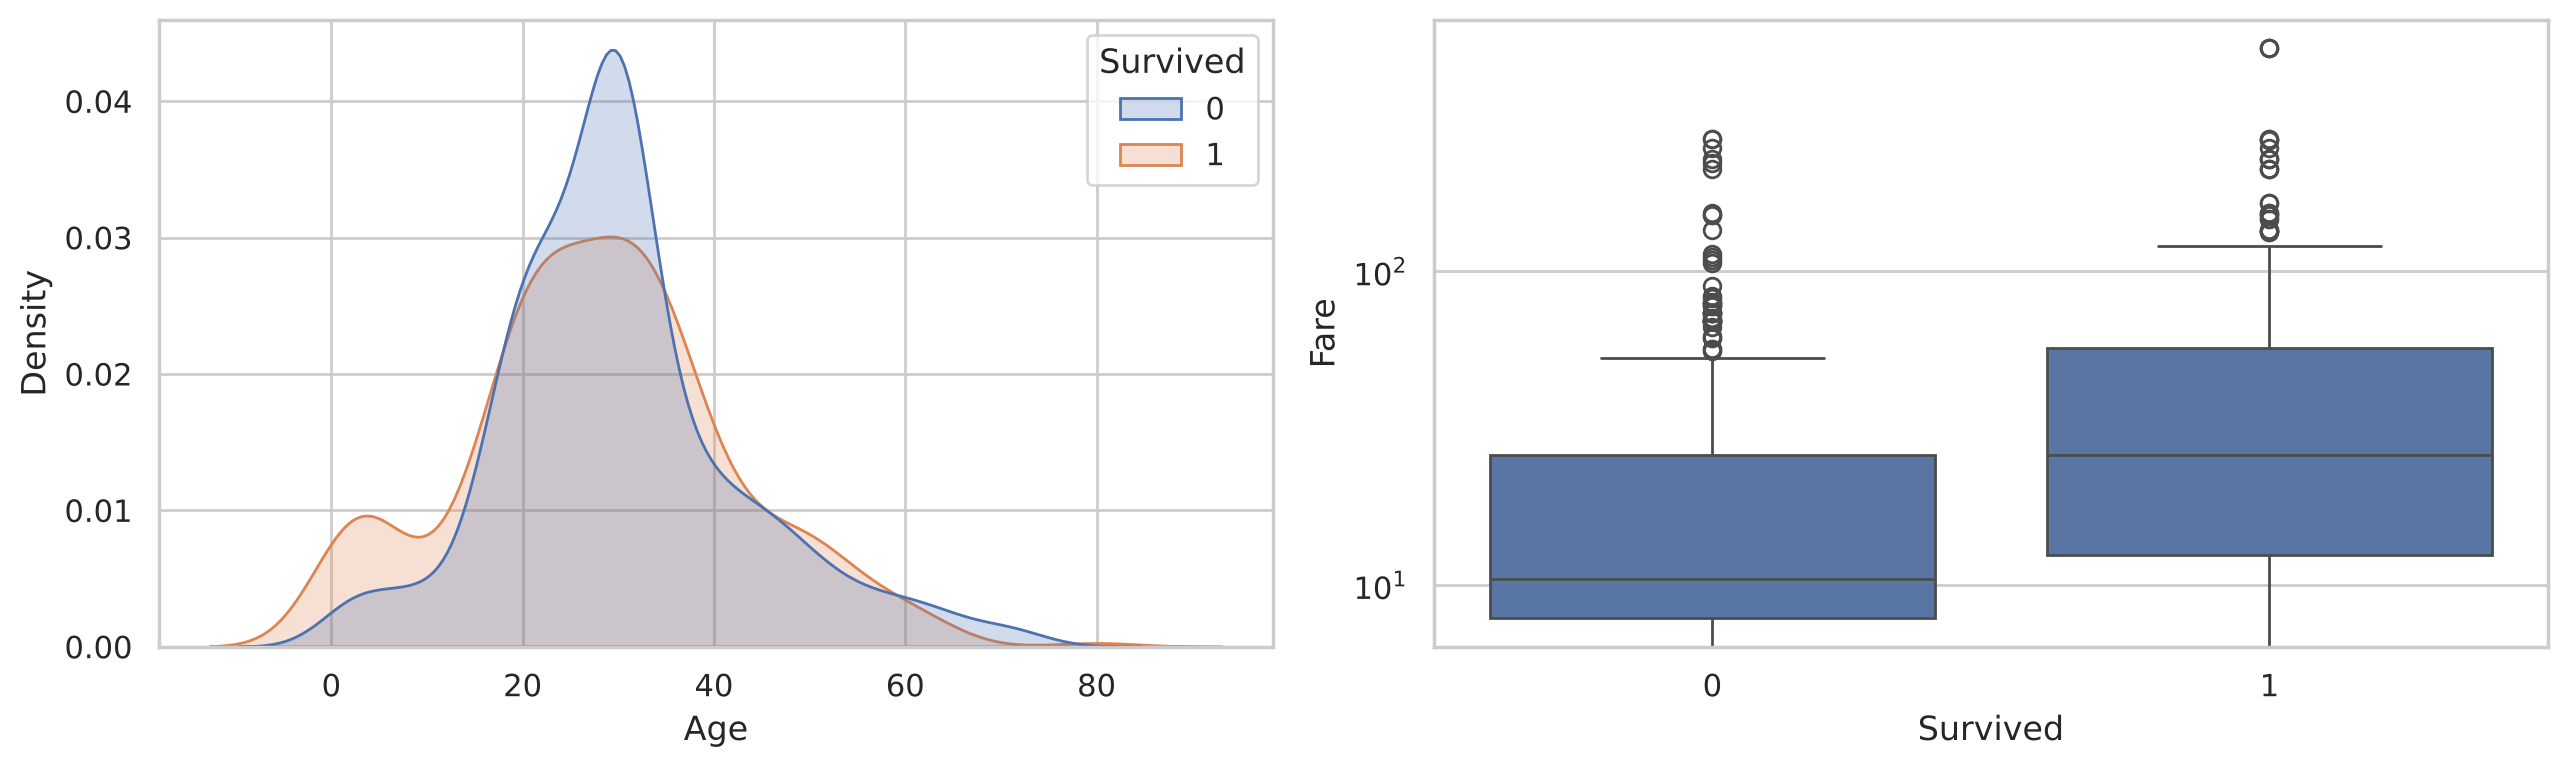

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x="Age", hue="Survived", fill=True, common_norm=False, ax=ax[0])
sns.boxplot(data=df, x="Survived", y="Fare", ax=ax[1]); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

             mean  count
FamilySize              
1           0.304    537
2           0.553    161
3           0.578    102
4           0.724     29
5           0.200     15
6           0.136     22
7           0.333     12
8           0.000      6
11          0.000      7


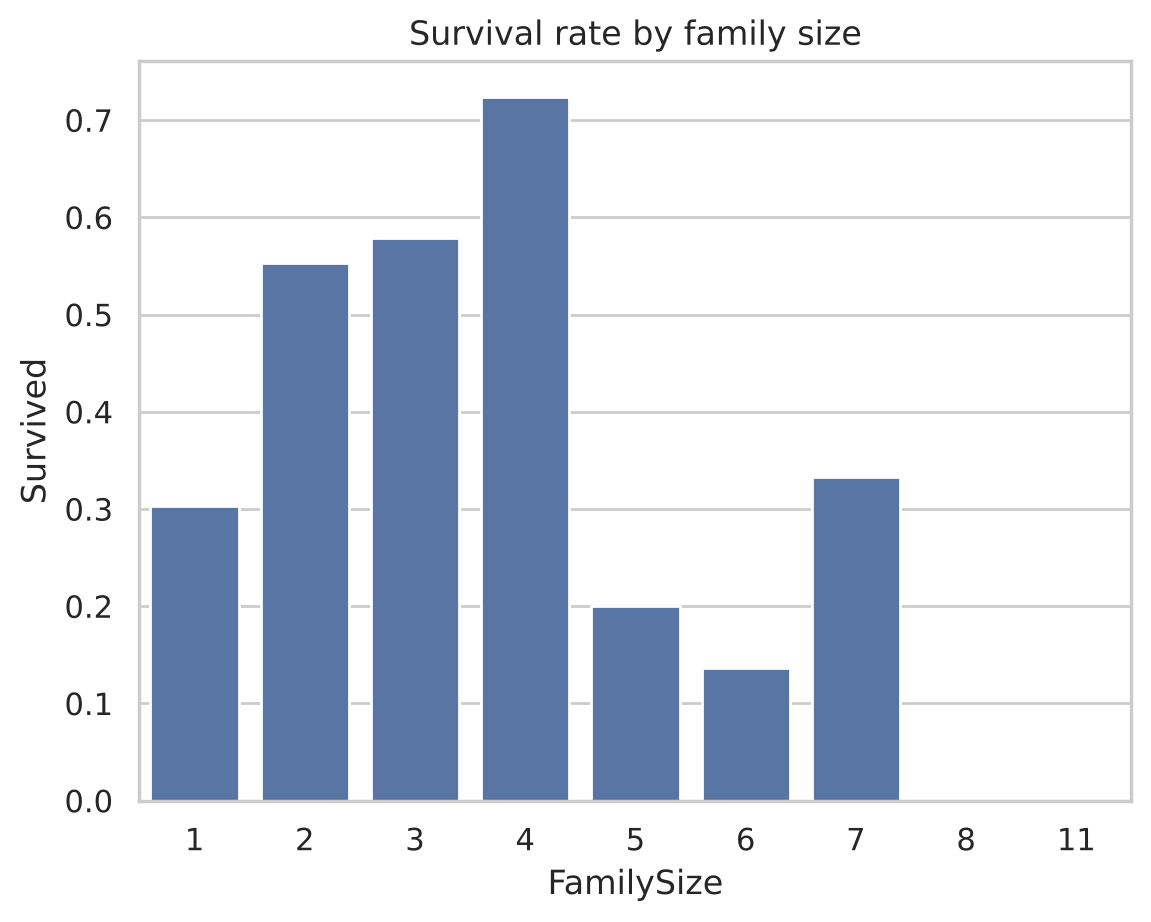

In [16]:
print(df.groupby("FamilySize")["Survived"].agg(["mean", "count"]).round(3))
sns.barplot(data=df, x="FamilySize", y="Survived", errorbar=None)
plt.title("Survival rate by family size"); plt.show()

## 5. Multivariate analysis

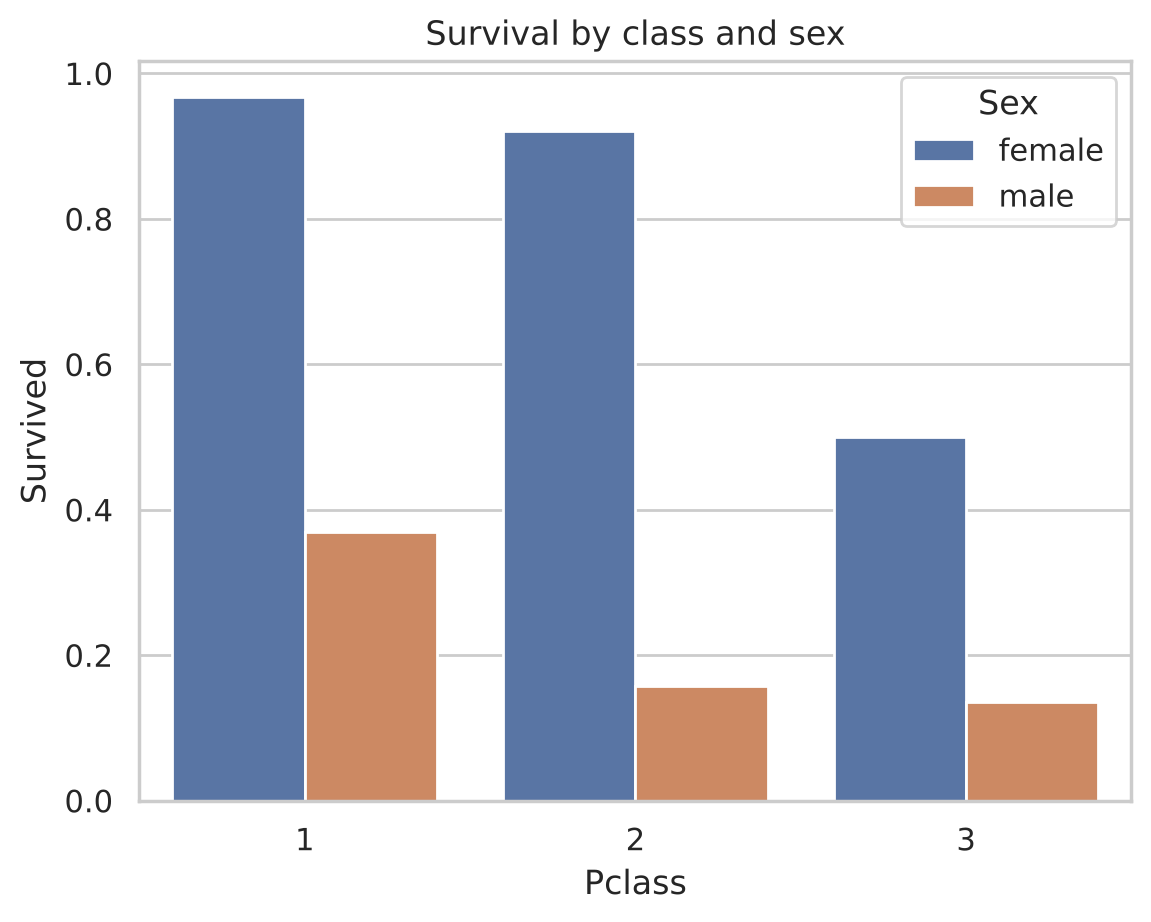

Pclass  Sex   
1       female    0.968
        male      0.369
2       female    0.921
        male      0.157
3       female    0.500
        male      0.135
Name: Survived, dtype: float64


In [17]:
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.title("Survival by class and sex"); plt.show()
print(df.groupby(["Pclass", "Sex"])["Survived"].mean().round(3))

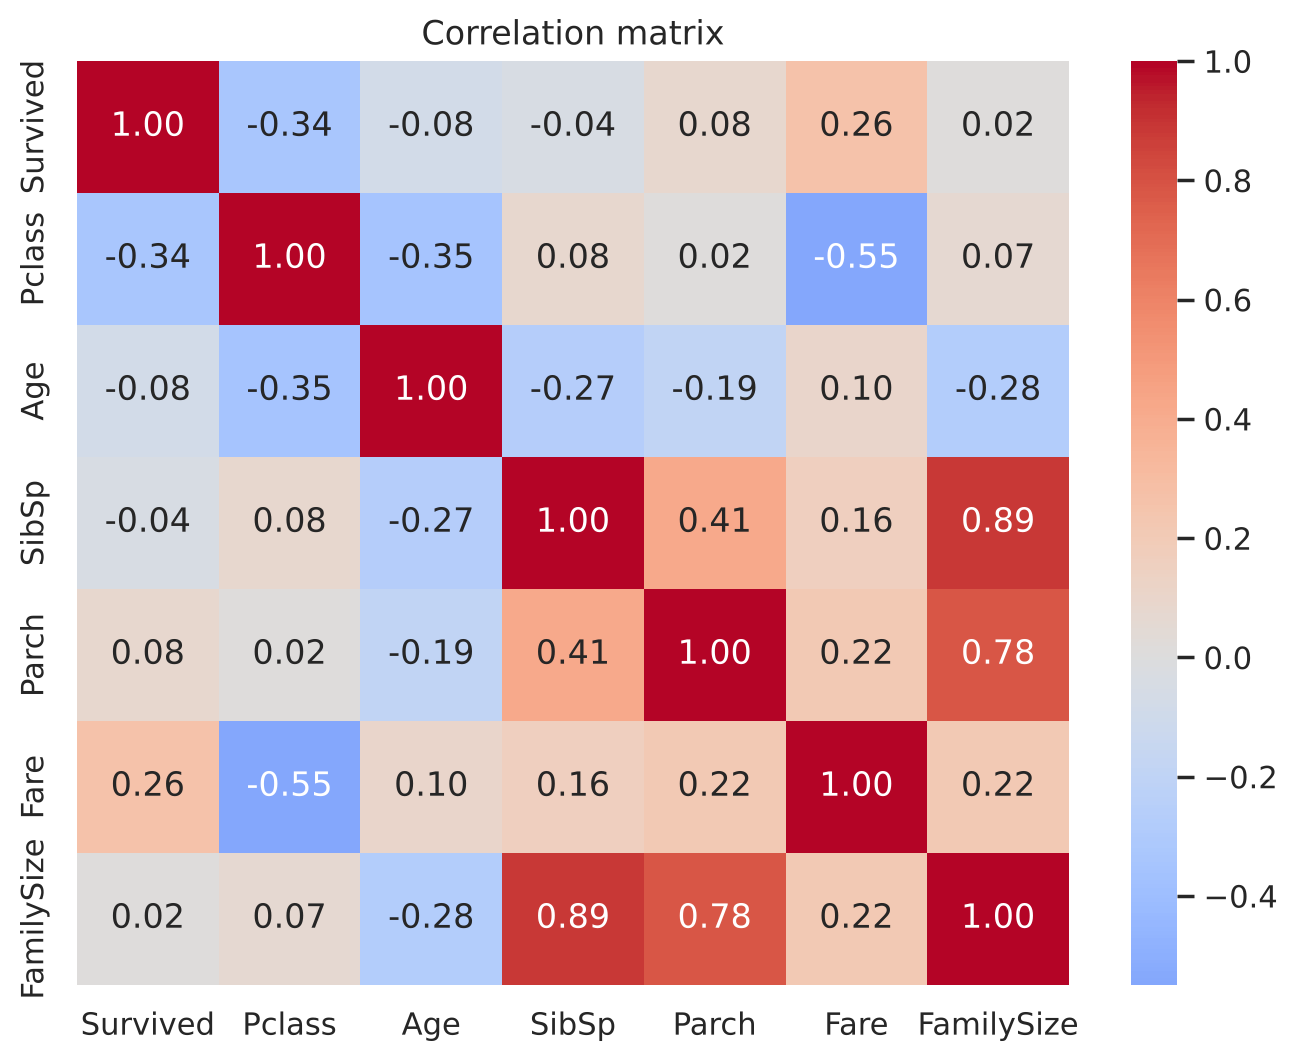

In [18]:
plt.figure(figsize=(8, 6))
num = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

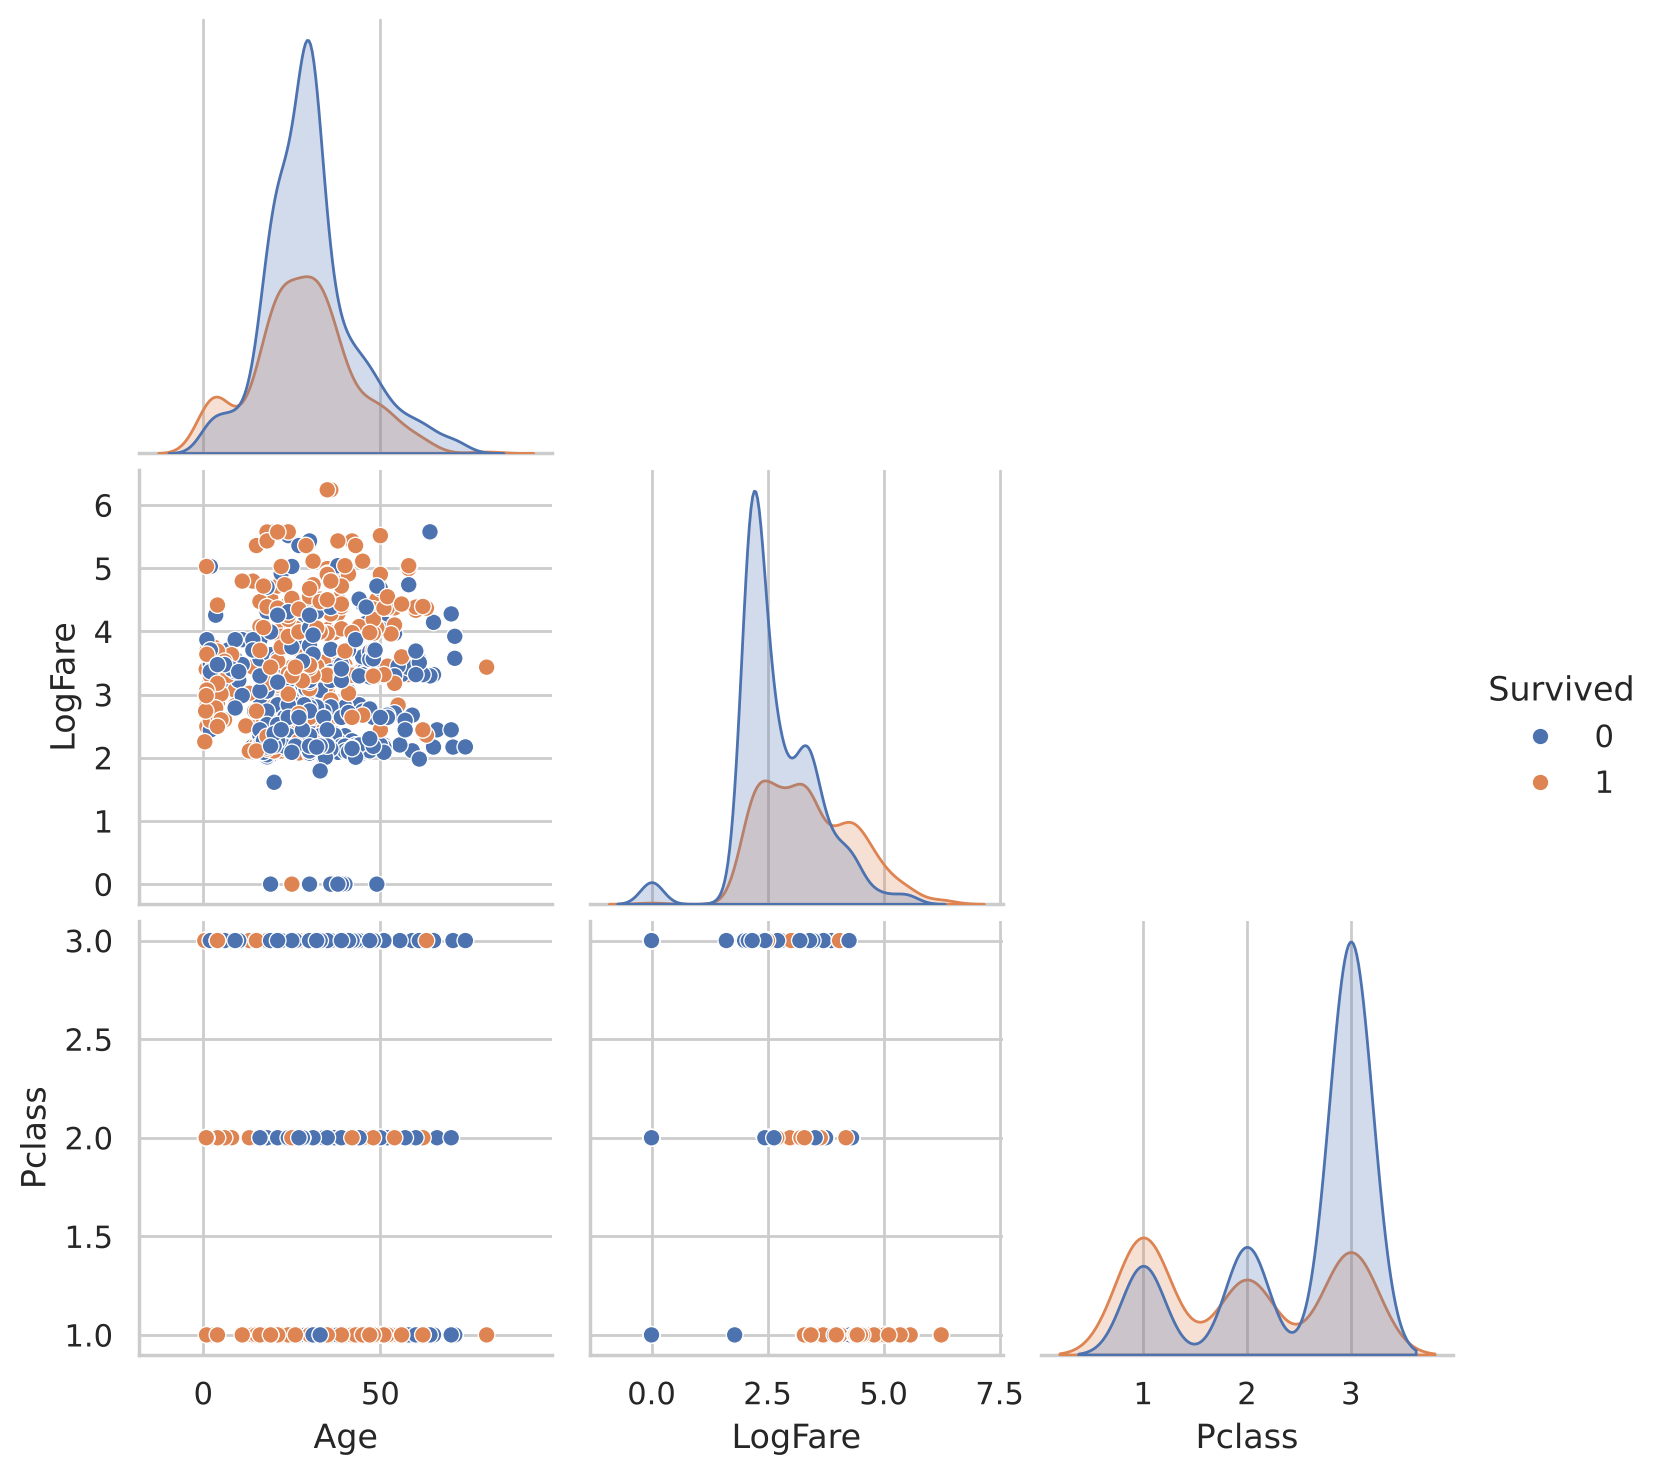

In [19]:
sns.pairplot(df[["Survived", "Age", "LogFare", "Pclass"]], hue="Survived", corner=True)
plt.show()

## 6. Key findings

| Pattern | Evidence |
|---|---|
| **Sex is the strongest factor** | Women survived at 74.2%, men at 18.9% |
| **Class matters** | 1st: 63%, 2nd: 47%, 3rd: 24% |
| **Class and sex interact** | 1st-class women 96.8%, 3rd-class men 13.5% |
| **Children had an edge** | Ages 0-12: 58% survival; over 60: 23% |
| **Family size has a sweet spot** | Alone: 30%; families of 2-4: 55-72%; 5 or more: 0-33% |
| **Port of embarkation** | Cherbourg 55%, Queenstown 39%, Southampton 34% (partly because Cherbourg had more 1st-class passengers) |
| **Cabin recorded** | 40% survival vs 12% without; mostly a proxy for 1st class |
| **Fare vs. class** | Fare correlates +0.26 with survival, class -0.34 |
| **Age alone is weak** | Correlation -0.08; it matters mainly for children |

**Conclusion:** survival followed the "women and children first" policy, with a strong overlay of socio-economic class. Sex and class together explain most of the variation.

**Limitations:** correlation is not causation, and imputed ages are estimates. Cabin and deck are only known for a minority of passengers.